# DLNM with Zero-Inflated Negative Binomial (PyMC)

This notebook reuses the original CrossBasis / smoother / tuning pipeline and only replaces the **final model** with a PyMC `ZeroInflatedNegativeBinomial`.

**Design choice (maximum reuse):**
- Model selection (`cb_tune`, `smoother_tune`, `alpha_tune`, `disp_tune`) still uses the original NegativeBinomial GLMGam.
- After the best settings are chosen, a single PyMC ZINB model is fitted.
- `pred_cal` and plotting helpers work with both a statsmodels result and a PyMC posterior.

You only need `data.csv` in the same folder (same columns as the original notebook).

In [3]:
%pip install pymc

   ---------------------------------------- 0.0/619.6 kB ? eta -:--:--
   ---------------------------------------- 619.6/619.6 kB 5.0 MB/s  0:00:00
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 10.7 MB/s  0:00:00
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   -------------------------- ------------- 1.3/2.0 MB 5.8 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 7.7 MB/s  0:00:00
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   -- ------------------------------------- 2.4/36.6 MB 13.0 MB/s eta 0:00:03
   ---- ----------------------------------- 4.5/36.6 MB 12.7 MB/s eta 0:00:03
   ------ --------------------------------- 6.3/36.6 MB 10.8 MB/s eta 0:00:03
   -------- ------------------------------- 7.9/36.6 MB 9.9 MB/s eta 0:00:03
   ------------ --------------------------- 11.3/36.6 MB 11.1 MB/s eta 0:00:03
   -------------- -------------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pygam 0.12.0 requires scipy<1.17,>=1.11.1, but you have scipy 1.18.1 which is incompatible.


In [4]:
%pip install arviz

Note: you may need to restart the kernel to use updated packages.


In [5]:
# ---------------------------------------------------------------------------
# Imports
# ---------------------------------------------------------------------------
import itertools
import warnings
from IPython.display import display, Markdown

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.gam.api import GLMGam
from statsmodels.gam.smooth_basis import (
    UnivariateBSplines,
    UnivariateCubicCyclicSplines,
    GenericSmoothers,
)

# Original DLNM helpers (keep whatever you already use)
try:
    from pydlnm.basis import CrossBasis
    from pydlnm.prediction import crosspred
except ImportError:
    CrossBasis = None
    crosspred = None
    print("Warning: pydlnm not found – CrossBasis / crosspred must be available in your environment.")

try:
    from dlnm import plot_crosspred, cb_pen
except ImportError:
    plot_crosspred = None
    cb_pen = None

# PyMC + ArviZ for the final ZINB model
import pymc as pm
import arviz as az

warnings.filterwarnings("ignore", category=FutureWarning)
print(f"PyMC {pm.__version__} | ArviZ {az.__version__}")

g++ not available, if using conda: `conda install gxx`


PyMC 6.4.0 | ArviZ 1.3.0


## 1. Original helper functions (unchanged or minimally touched)

In [6]:
def cb_construct(dataframe, col_lst, max_lag, setting_lst):
    """Build CrossBasis matrices and append them to a lagged-truncated data frame."""
    var_degree, var_df, lag_degree, lag_df = setting_lst

    cb_list = []
    for col in col_lst:
        cb = CrossBasis(
            dataframe[col].values,
            lag=max_lag,
            argvar={"fun": "bs", "degree": var_degree, "df": var_df},
            arglag={"fun": "bs", "degree": lag_degree, "df": lag_df},
        )
        cb_list.append(cb)

    X_exposure = np.concatenate([np.asarray(cb) for cb in cb_list], axis=1)
    n_basis_per_exp = X_exposure.shape[1] // len(col_lst)
    exp_name_list = [f"{col}_basis_{i}" for col in col_lst for i in range(n_basis_per_exp)]

    base = dataframe.reset_index(drop=True).iloc[max_lag:].copy()
    basis_df = pd.DataFrame(X_exposure[max_lag:], columns=exp_name_list, index=base.index)
    model_data = pd.concat([base, basis_df], axis=1)
    return model_data, exp_name_list, cb_list

In [7]:
def smoother_construct(dataframe, bs_dict, ccs_dict):
    """Build GenericSmoothers object exactly as in the original notebook."""
    bs_list = []
    for i, name in enumerate(bs_dict["name"]):
        bs = UnivariateBSplines(
            dataframe[name].values,
            df=bs_dict["df"][i],
            degree=bs_dict["degree"][i],
            variable_name=name,
            include_intercept=False,
        )
        bs_list.append(bs)

    ccs_list = []
    for i, name in enumerate(ccs_dict["name"]):
        ccs = UnivariateCubicCyclicSplines(
            dataframe[name].values,
            df=ccs_dict["df"][i],
            variable_name=name,
            constraints="center",
        )
        ccs_list.append(ccs)

    sm_weights = bs_list + ccs_list
    smooth_names = list(bs_dict["name"]) + list(ccs_dict["name"])
    X_smooth = dataframe[smooth_names]
    return GenericSmoothers(X_smooth, sm_weights)

In [8]:
def model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para):
    """Original NegativeBinomial GLMGam – kept for model *selection* / tuning."""
    terms = list(exp_names) + list(linear_predictors)
    formula = f"{tar_var} ~ {' + '.join(terms)}"
    alpha = np.asarray(alpha, dtype=float)

    model = GLMGam.from_formula(
        formula,
        data=dataframe,
        smoother=smoothers,
        alpha=alpha,
        family=sm.families.NegativeBinomial(alpha=disp_para),
    )
    result = model.fit()
    return model, result

In [9]:
def cb_tune(dataframe, tar_var, exp_col, linear_predictors, bs_dict, ccs_dict,
            alpha, disp_para, max_lag, grid):
    print(f"{'='*10} Tuning CrossBasis settings {'='*10}")
    best_idx = 0
    performance = []

    for option in grid:
        model_data, exp_names, _ = cb_construct(dataframe, exp_col, max_lag, option)
        smoothers = smoother_construct(model_data, bs_dict, ccs_dict)
        try:
            _, result = model_construct(
                model_data, tar_var, exp_names, linear_predictors,
                smoothers, alpha, disp_para,
            )
            bic = result.bic
        except Exception as e:
            print(f"option {option} failed: {e}")
            bic = np.inf
        performance.append(bic)
        msg = f"BIC for {option}: {bic:.2f}" if np.isfinite(bic) else f"BIC for {option}: failed"
        print(msg)

    for i in range(1, len(performance)):
        if performance[i] < performance[best_idx]:
            best_idx = i

    best_setting = grid[best_idx]
    print(f"Best CrossBasis setting: {best_setting} (BIC = {performance[best_idx]:.2f})")
    return cb_construct(dataframe, exp_col, max_lag, best_setting)

In [10]:
def smoother_tune(dataframe, tar_var, exp_names, linear_predictors, alpha, disp_para,
                  bs_name_lst, ccs_name_lst, grid):
    print(f"\n{'='*10} Tuning smoother degrees of freedom {'='*10}")
    n_bs = len(bs_name_lst)
    best_idx = 0
    performance = []

    for option in grid:
        bs_dfs = list(option[:n_bs])
        ccs_dfs = list(option[n_bs:])

        bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": bs_dfs}
        ccs_dict = {"name": ccs_name_lst, "df": ccs_dfs}

        smoothers = smoother_construct(dataframe, bs_dict, ccs_dict)
        try:
            _, result = model_construct(
                dataframe, tar_var, exp_names, linear_predictors,
                smoothers, alpha, disp_para,
            )
            bic = result.bic
            edf = float(np.sum(result.edf))
        except Exception as e:
            print(f"option {option} failed: {e}")
            bic, edf = np.inf, np.nan

        performance.append((bic, edf))
        print(f"Degrees of freedom {option}: BIC={bic:.4f} | sum(EDF)={edf:.4f}")

    for i in range(1, len(performance)):
        if performance[i][0] < performance[best_idx][0]:
            best_idx = i

    best_option = grid[best_idx]
    print(f"Best smoother setting: {best_option} (BIC={performance[best_idx][0]:.4f})")

    bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": list(best_option[:n_bs])}
    ccs_dict = {"name": ccs_name_lst, "df": list(best_option[n_bs:])}
    return smoother_construct(dataframe, bs_dict, ccs_dict), bs_dict, ccs_dict

In [11]:
def alpha_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers,
               start_alpha, disp_para, criterion_lst=["bic", "gcv"], method="nm"):
    print(f"\n{'='*10} Tuning smoother weights (α) {'='*10}")
    start_alpha = np.asarray(start_alpha, dtype=float)
    model, _ = model_construct(dataframe, tar_var, exp_names, linear_predictors,
                               smoothers, start_alpha, disp_para)

    alpha_out_lst = []
    for criterion in criterion_lst:
        best_alpha = model.select_penweight(criterion=criterion, method=method,
                                            start_params=start_alpha)
        if isinstance(best_alpha, (list, tuple)):
            candidate = best_alpha[0]
            alpha_out = np.asarray(candidate if np.ndim(candidate) > 0 else best_alpha, dtype=float)
        else:
            alpha_out = np.asarray(best_alpha, dtype=float).ravel()
        alpha_out_lst.append(alpha_out)
        print(f"Best alpha found with {criterion}: {alpha_out}")

    # ensure derivative bases exist (original safeguard)
    for s in smoothers.smoothers:
        if getattr(s, "der_basis", None) is None:
            s.der_basis = np.zeros_like(s.basis)
        if getattr(s, "der2_basis", None) is None:
            s.der2_basis = np.zeros_like(s.basis)

    try:
        best_a_kfold = model.select_penweight_kfold()
        alpha_out_lst.append(best_a_kfold[0])
        print(f"Best alpha found with Kfold: {best_a_kfold[0]}")
    except Exception as e:
        print(f"Kfold alpha selection failed: {e}")
        alpha_out_lst.append(alpha_out_lst[0])

    # comparison table
    results = {}
    for name, a in zip(["BIC", "GCV", "KFold"], alpha_out_lst):
        try:
            _, res = model_construct(dataframe, tar_var, exp_names, linear_predictors,
                                    smoothers, a, disp_para)
            results[name] = {
                "alpha": a,
                "AIC": res.aic,
                "BIC": res.bic,
                "GCV": getattr(res, "gcv", np.nan),
                "EDF": res.edf.sum(),
            }
        except Exception:
            results[name] = {"alpha": a, "AIC": np.nan, "BIC": np.nan, "GCV": np.nan, "EDF": np.nan}

    print("Alpha values comparison:")
    display(pd.DataFrame(results).T)
    return alpha_out_lst[0]   # return BIC-selected alpha

In [12]:
def disp_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_grid):
    print(f"\n{'='*10} Tuning Negative Binomial dispersion parameter {'='*10}")
    performance = []

    for disp in disp_grid:
        try:
            _, result = model_construct(
                dataframe, tar_var, exp_names, linear_predictors,
                smoothers, alpha, disp,
            )
            pearson_ratio = result.pearson_chi2 / result.df_resid
            performance.append((disp, pearson_ratio, result.bic))
            print(f"Dispersion {disp:5.1f}: Pearson ratio = {pearson_ratio:.4f} | BIC = {result.bic:.4f}")
        except Exception as e:
            print(f"Dispersion {disp} failed: {e}")

    if not performance:
        raise RuntimeError("All dispersion values failed.")

    best = min(performance, key=lambda x: abs(x[1] - 1.0))
    print(f"\nBest dispersion parameter: {best[0]} (Pearson ratio = {best[1]:.4f})")
    return best[0]

## 2. New PyMC ZINB helpers

In [13]:
def extract_smoother_bases(smoothers):
    """
    Pull the actual basis matrices out of a GenericSmoothers object
    so we can build a full design matrix for PyMC.
    Returns a list of (name, basis_array) tuples.
    """
    bases = []
    for s in smoothers.smoothers:
        name = getattr(s, "variable_name", "smooth")
        # statsmodels Univariate* objects store the evaluated basis in .basis
        B = np.asarray(s.basis)
        bases.append((name, B))
    return bases


def build_full_design_matrix(model_data, exp_name_list, linear_predictors_list, smoothers):
    """
    Construct the complete design matrix that GLMGam would have used internally:
    CrossBasis columns + linear predictors + all smoother bases.
    """
    parts = []
    col_names = []

    # 1. Cross-basis columns (already present in model_data)
    X_cb = model_data[exp_name_list].values
    parts.append(X_cb)
    col_names.extend(exp_name_list)

    # 2. Linear predictors
    X_lin = model_data[linear_predictors_list].values
    parts.append(X_lin)
    col_names.extend(linear_predictors_list)

    # 3. Smoother bases
    for name, B in extract_smoother_bases(smoothers):
        parts.append(B)
        col_names.extend([f"{name}_s{i}" for i in range(B.shape[1])])

    X = np.column_stack(parts)
    # drop any constant / all-zero columns that can appear after lag truncation
    keep = np.std(X, axis=0) > 1e-12
    X = X[:, keep]
    col_names = [c for c, k in zip(col_names, keep) if k]

    return X, col_names

In [14]:
def model_construct_zinb(model_data, tar_var, exp_name_list, linear_predictors_list,
                         smoothers, prior_sigma=2.0, psi_prior="constant",
                         draws=1000, tune=1000, target_accept=0.9, cores=2,
                         random_seed=42):
    """
    Fit a Zero-Inflated Negative Binomial model with PyMC using the same
    design matrix that the original GLMGam would have used.

    Parameters
    ----------
    psi_prior : {"constant", "logistic"}
        - "constant"  → single global psi (recommended starting point)
        - "logistic"  → psi depends on the same design matrix via a logit link

    Returns
    -------
    model   : pm.Model
    idata   : arviz.InferenceData
    X       : ndarray          (the design matrix that was used)
    colnames: list of str
    """
    y = model_data[tar_var].values.astype("float64")
    X, colnames = build_full_design_matrix(
        model_data, exp_name_list, linear_predictors_list, smoothers
    )
    n_obs, n_coef = X.shape
    print(f"Design matrix shape for ZINB: {X.shape}")

    coords = {"coef": colnames, "obs": np.arange(n_obs)}

    with pm.Model(coords=coords) as model:
        # data containers (optional but useful for posterior predictive later)
        X_data = pm.Data("X", X, dims=("obs", "coef"))
        y_data = pm.Data("y", y, dims="obs")

        # coefficients for the count mean (log link)
        beta = pm.Normal("beta", mu=0.0, sigma=prior_sigma, dims="coef")

        eta = pm.math.dot(X_data, beta)
        mu = pm.math.exp(eta)

        # zero-inflation probability
        if psi_prior == "constant":
            psi = pm.Beta("psi", alpha=2.0, beta=2.0)
        else:  # logistic
            gamma = pm.Normal("gamma", mu=0.0, sigma=1.0, dims="coef")
            logit_psi = pm.math.dot(X_data, gamma)
            psi = pm.Deterministic("psi", pm.math.invlogit(logit_psi), dims="obs")

        # dispersion (shape) of the NB component
        alpha = pm.HalfNormal("alpha", sigma=5.0)

        # likelihood
        pm.ZeroInflatedNegativeBinomial(
            "y_obs",
            psi=psi,
            mu=mu,
            alpha=alpha,
            observed=y_data,
            dims="obs",
        )

        print("Sampling ZINB model …")
        idata = pm.sample(
            draws=draws,
            tune=tune,
            target_accept=target_accept,
            cores=cores,
            random_seed=random_seed,
            return_inferencedata=True,
            progressbar=True,
        )

    return model, idata, X, colnames

In [15]:
def extract_cb_coef_from_idata(idata, colnames, exp_name, return_vcov=True):
    """
    Extract posterior mean (and optional covariance) of the CrossBasis
    coefficients that belong to a given exposure from a PyMC InferenceData.
    """
    basis_names = [n for n in colnames if n.startswith(f"{exp_name}_basis_")]
    if not basis_names:
        raise ValueError(f"No basis coefficients found for exposure '{exp_name}'.")

    # posterior samples of beta: (chain, draw, coef)
    beta_samples = idata.posterior["beta"].sel(coef=basis_names).values
    # flatten chains
    beta_flat = beta_samples.reshape(-1, len(basis_names))

    coef_mean = beta_flat.mean(axis=0)
    if return_vcov:
        vcov = np.cov(beta_flat, rowvar=False)
        return coef_mean, vcov, basis_names
    return coef_mean, None, basis_names

## 3. Prediction & plotting (updated to accept both statsmodels and PyMC)

In [16]:
def pred_cal(result_or_idata, cb_list, dataframe, exp_col_list, exp_idx=0,
             colnames=None):
    """
    Compute cross-prediction for one exposure.

    Accepts either:
      - a classic statsmodels result object, or
      - a PyMC InferenceData (in which case colnames must be supplied).
    """
    exp = exp_col_list[exp_idx]

    if hasattr(result_or_idata, "params"):  # statsmodels path (kept for compatibility)
        param_names = list(result_or_idata.params.index)
        basis_names = [n for n in param_names if n.startswith(f"{exp}_basis_")]
        if not basis_names:
            raise ValueError(f"No basis coefficients found for exposure '{exp}'.")
        cb_coef = result_or_idata.params[basis_names].values
        cb_vcov = result_or_idata.cov_params().loc[basis_names, basis_names].values
    else:  # PyMC InferenceData path
        if colnames is None:
            raise ValueError("colnames must be provided when using a PyMC idata.")
        cb_coef, cb_vcov, _ = extract_cb_coef_from_idata(
            result_or_idata, colnames, exp, return_vcov=True
        )

    at = np.linspace(dataframe[exp].min(), dataframe[exp].max(), 100)
    cen = float(dataframe[exp].median())

    pred = crosspred(
        basis=cb_list[exp_idx],
        coef=cb_coef,
        vcov=cb_vcov,
        model_link="log",
        at=at,
        cen=cen,
    )
    print(f"{exp} RR range: {pred.allRRfit.min():.3f} to {pred.allRRfit.max():.3f}")
    return pred, exp, cen

In [17]:
def graph_3Dplot(pred, exp_name):
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping 3-D plot.")
        return
    fig = plot_crosspred(pred, ptype="3d")
    ax = fig.gca()
    ax.set_title("3D Exposure-Lag-Response Association Surface", fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel(exp_name, fontsize=12, labelpad=10)
    ax.set_ylabel("Lag (Weeks)", fontsize=12, labelpad=10)
    ax.set_zlabel("Relative Risk (RR)", labelpad=10)
    try:
        collections = ax.collections[0]
        vmin, vmax = collections.get_array().min(), collections.get_array().max()
        collections.set_clim(vmin, vmax)
        cbar = fig.colorbar(collections, ax=ax, shrink=0.6, pad=0.1)
        cbar.set_label("Relative Risk (RR)", rotation=270, labelpad=20)
    except Exception:
        pass
    plt.tight_layout()
    plt.show()


def graph_exp_plot(pred, exp_name, cen):
    if plot_crosspred is None:
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(pred.at, pred.allRRfit, color="C0", lw=2)
        if hasattr(pred, "allRRlow") and hasattr(pred, "allRRhigh"):
            ax.fill_between(pred.at, pred.allRRlow, pred.allRRhigh, alpha=0.25, color="C0")
        ax.axhline(1, color="gray", ls="--", alpha=0.7)
        ax.axvline(cen, color="black", ls=":", lw=1.2, label=f"Centering {exp_name} ({cen:.4f})")
        ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=12)
        ax.set_xlabel(exp_name, fontsize=12)
        ax.set_ylabel("Relative Risk (RR)", fontsize=12)
        ax.legend(loc="best")
        plt.tight_layout()
        plt.show()
        return

    fig = plot_crosspred(pred, ptype="overall")
    ax = fig.gca()
    ax.axvline(x=cen, color="black", linestyle=":", linewidth=1.2,
               label=f"Centering {exp_name} ({cen:.4f})")
    ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=15)
    ax.set_xlabel(exp_name, fontsize=12)
    ax.legend(loc="best", frameon=True)
    plt.show()


def graph_lag_plot(pred, tar_val, exp_name):
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping lag-slice plot.")
        return
    fig = plot_crosspred(pred, ptype="slices", var=tar_val)
    ax = fig.gca()
    ax.set_title(f"Lag-Response Curve at {exp_name} = {tar_val:.4f}",
                 fontsize=14, fontweight="bold")
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color="gray", linestyle="--", alpha=0.7)
    plt.show()


def graph_plot(pred, exp_name, cen, lag_slice_val=None):
    graph_3Dplot(pred, exp_name)
    graph_exp_plot(pred, exp_name, cen)
    if lag_slice_val is None:
        lag_slice_val = cen
    graph_lag_plot(pred, lag_slice_val, exp_name)

In [18]:
def model_metric_zinb(idata):
    """Simple summary of the PyMC ZINB fit."""
    print("=== PyMC ZINB posterior summary (selected parameters) ===")
    print(az.summary(idata, var_names=["psi", "alpha"], round_to=3))
    # optional WAIC / LOO
    try:
        waic = az.waic(idata)
        loo = az.loo(idata)
        print(f"\nWAIC: {waic.elpd_waic:.2f}  (SE {waic.se:.2f})")
        print(f"LOO : {loo.elpd_loo:.2f}  (SE {loo.se:.2f})")
    except Exception as e:
        print(f"WAIC/LOO computation skipped: {e}")

## 4. Main DLNM driver (tuning with original NB, final fit with ZINB)

In [19]:
def DLNM_ZINB(dataframe, max_lag, tar_var, exp_col_list, linear_predictors_list,
              bs_name_lst, ccs_name_lst, cb_grid, smoother_grid, disp_grid,
              criterion_lst=["bic", "gcv"],
              # PyMC sampling controls
              draws=800, tune=800, target_accept=0.9, cores=2,
              psi_prior="constant", prior_sigma=2.0):
    """
    Full pipeline:
      1. Tune CrossBasis, smoothers, alpha, dispersion with the original
         NegativeBinomial GLMGam (fast, re-uses all your existing cells).
      2. Fit the final model as a PyMC Zero-Inflated Negative Binomial.
      3. Produce the usual cross-prediction plots.
    """
    n_smooth = len(bs_name_lst) + len(ccs_name_lst)
    initial_alpha = np.asarray([200.0] * n_smooth, dtype=float)
    initial_disp = 1.0

    init_bs_dict = {"name": bs_name_lst, "degree": [3] * len(bs_name_lst),
                    "df": [6] * len(bs_name_lst)}
    init_ccs_dict = {"name": ccs_name_lst, "df": [4] * len(ccs_name_lst)}

    # ---------- 1. Original tuning (NB) ----------
    model_data, exp_name_list, cb_list = cb_tune(
        dataframe, tar_var, exp_col_list, linear_predictors_list,
        init_bs_dict, init_ccs_dict, initial_alpha, initial_disp, max_lag, cb_grid
    )

    smoothers, best_bs_dict, best_ccs_dict = smoother_tune(
        model_data, tar_var, exp_name_list, linear_predictors_list,
        initial_alpha, initial_disp, bs_name_lst, ccs_name_lst, smoother_grid
    )

    best_alpha = alpha_tune(
        model_data, tar_var, exp_name_list, linear_predictors_list,
        smoothers, initial_alpha, initial_disp, criterion_lst, method="nm"
    )

    best_disp = disp_tune(
        model_data, tar_var, exp_name_list, linear_predictors_list,
        smoothers, best_alpha, disp_grid
    )

    # (optional) keep the classic NB fit for comparison
    print("\n--- Classic NB GLMGam (for reference) ---")
    _, nb_result = model_construct(
        model_data, tar_var, exp_name_list, linear_predictors_list,
        smoothers, best_alpha, best_disp
    )
    print(nb_result.summary().tables[1])

    # ---------- 2. Final PyMC ZINB ----------
    print(f"\n{'='*15} Final PyMC Zero-Inflated Negative Binomial {'='*15}")
    zinb_model, idata, X, colnames = model_construct_zinb(
        model_data, tar_var, exp_name_list, linear_predictors_list,
        smoothers,
        prior_sigma=prior_sigma,
        psi_prior=psi_prior,
        draws=draws,
        tune=tune,
        target_accept=target_accept,
        cores=cores,
    )

    model_metric_zinb(idata)

    # ---------- 3. Prediction & plots ----------
    pred, exp_name, cen = pred_cal(
        idata, cb_list, model_data, exp_col_list, exp_idx=0, colnames=colnames
    )
    graph_plot(pred, exp_name, cen, lag_slice_val=cen)

    return idata, pred, model_data, cb_list, colnames, nb_result

## 5. Data loading & settings (identical to original)

In [20]:
# Import data and basic settings
df = pd.read_csv("data.csv")
df.columns = [
    "Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV",
    "H1", "H3", "B", "AandB", "ContainmentHealthIndex_Average", "pandemic_flag",
]

df.drop(columns=["From"], inplace=True)
df["time"] = np.arange(1, len(df) + 1)

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]
spline_col = ["ContainmentHealthIndex_Average", "Week", "time"]

In [21]:
# Overview (optional)
display(df.head())
df.info()
display(df.describe())

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,time
0,2002,36,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,1,12,3.0,19,0.0,0.0,1
1,2002,37,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,0,6,4.0,15,0.0,0.0,2
2,2002,38,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,0,4,4.0,13,0.0,0.0,3
3,2002,39,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,0,2,6.0,10,0.0,0.0,4
4,2002,40,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,0,6,2.0,8,0.0,0.0,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1253 entries, 0 to 1252
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            1253 non-null   int64  
 1   Week                            1253 non-null   int64  
 2   temprange                       1253 non-null   float64
 3   temp                            1253 non-null   float64
 4   RH                              1253 non-null   float64
 5   SR                              1253 non-null   float64
 6   AP                              1253 non-null   float64
 7   DPT                             1253 non-null   float64
 8   WS                              1253 non-null   float64
 9   UV                              1253 non-null   float64
 10  H1                              1253 non-null   int64  
 11  H3                              1253 non-null   int64  
 12  B                               12

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,time
count,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1252.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,2014.172386,26.605746,14.864006,23.383599,78.736233,13.996983,1012.860774,19.225339,10.074062,2.891700,69.613727,115.727055,44.593450,261.437350,8.128132,0.131684,627.000000
std,6.945058,15.077257,3.539967,5.005770,8.494599,5.270534,6.067874,5.963239,1.811932,1.256406,189.083854,233.728958,131.615377,439.621172,21.983305,0.338282,361.854252
min,2002.000000,1.000000,3.900000,8.900000,43.000000,2.020000,996.750000,-0.100000,5.550000,0.400000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2008.000000,14.000000,12.200000,19.100000,74.500000,9.930000,1008.000000,14.900000,8.800000,2.000000,0.000000,5.000000,3.000000,27.000000,0.000000,0.000000,314.000000
50%,2014.000000,27.000000,14.000000,24.400000,80.000000,14.240000,1012.800000,20.500000,10.000000,3.000000,4.000000,28.000000,12.500000,103.000000,0.000000,0.000000,627.000000
75%,2020.000000,40.000000,17.000000,28.000000,85.000000,17.680000,1017.650000,24.800000,11.200000,4.000000,47.000000,125.000000,41.000000,305.000000,0.000000,0.000000,940.000000
max,2026.000000,53.000000,27.700000,31.700000,94.000000,26.460000,1027.700000,26.800000,17.800000,7.000000,1999.000000,2560.000000,1978.000000,4679.000000,82.140000,1.000000,1253.000000


In [22]:
df_pop = pd.read_csv("Population.csv")

df_pop = df_pop.iloc[[3, 4, 6]]
df_pop.drop(columns=["Unnamed: 1"], inplace=True)
df_pop = df_pop.T
df_pop.index = range(df_pop.shape[0])
df_pop.columns = ["Year", "Reference time-point", "Population"]
df_pop.drop([0], inplace=True)
display(df_pop.head())
df_pop.info()
df_pop["Year"] = pd.to_numeric(df_pop["Year"])


,Year,Reference time-point,Population
1,2002,Mid-year,6744.1
2,2002,Year-end,6725.8
3,2003,Mid-year,6730.8
4,2003,Year-end,6764.2
5,2004,Mid-year,6783.5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 1 to 49
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Year                  49 non-null     object
 1   Reference time-point  49 non-null     object
 2   Population            49 non-null     object
dtypes: object(3)
memory usage: 1.3+ KB


In [23]:
df["Reference time-point"] = np.where(df["Week"] >= 23, "Year-end", "Mid-year")

df = pd.merge(df, df_pop, on=["Year", "Reference time-point"], how="left")

df.loc[df[df["Population"].isna()].index, "Population"] = df_pop.loc[df_pop[df_pop["Year"]==2026].index, "Population"].values[0]
df["Population"] = pd.to_numeric(df["Population"])
df["Log_population"] = np.log(df["Population"])

df.drop(columns="Reference time-point", inplace=True)


In [24]:
no_school_index = df[((df["Week"] >= 31) & (df["Week"] <= 35))].index
df.loc[no_school_index, "school_flag"] = 0
df.fillna({"school_flag": 1}, inplace=True)

In [25]:
# Model specification (same as original)
linear_predictors_list = ["pandemic_flag", "Log_population", "school_flag"]
bs_name_lst = ["time", "ContainmentHealthIndex_Average"]
ccs_name_lst = ["Week"]

cb_grid = list(itertools.product([2, 3], [3, 4, 5, 6], [2, 3], [3, 4, 5, 6]))
smoother_grid = list(itertools.product([5, 6, 7, 8], [4, 5, 6, 7, 8], [3, 4, 5, 6]))
disp_grid = [0.5, 1.0, 1.5, 2.0, 3.0, 5.0]

## 6. Run the pipeline

Only the final model is ZINB; everything before that is identical to your original notebook.

In [ ]:
# Most common sources of the message
warnings.filterwarnings("ignore", message=".*Singular matrix.*")
warnings.filterwarnings("ignore", message=".*singular matrix.*")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="statsmodels")

**============================== temprange (ZINB) ==============================**

========== Tuning CrossBasis settings ==========


c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_result

BIC for (2, 3, 2, 3): 9569.05


c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_result

BIC for (2, 3, 2, 4): 9591.50


... (196 outputs left out)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [beta, psi, alpha]


Output()

Sampling 2 chains for 600 tune and 600 draw iterations (1_200 + 1_200 draws total) took 134 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


=== PyMC ZINB posterior summary (selected parameters) ===
        mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  \
psi    0.991  0.007     0.978     0.998  1232.086   703.877  1.005        0.0   
alpha  0.406  0.020     0.376     0.440  1858.067   872.070  1.003        0.0   

       mcse_sd  
psi      0.000  
alpha    0.001  
WAIC/LOO computation skipped: module 'arviz' has no attribute 'waic'
temprange RR range: 0.248 to 230.174


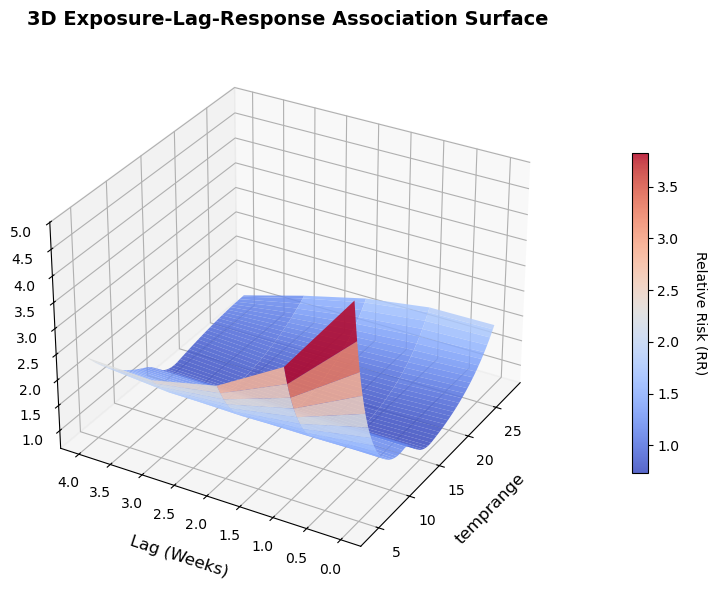

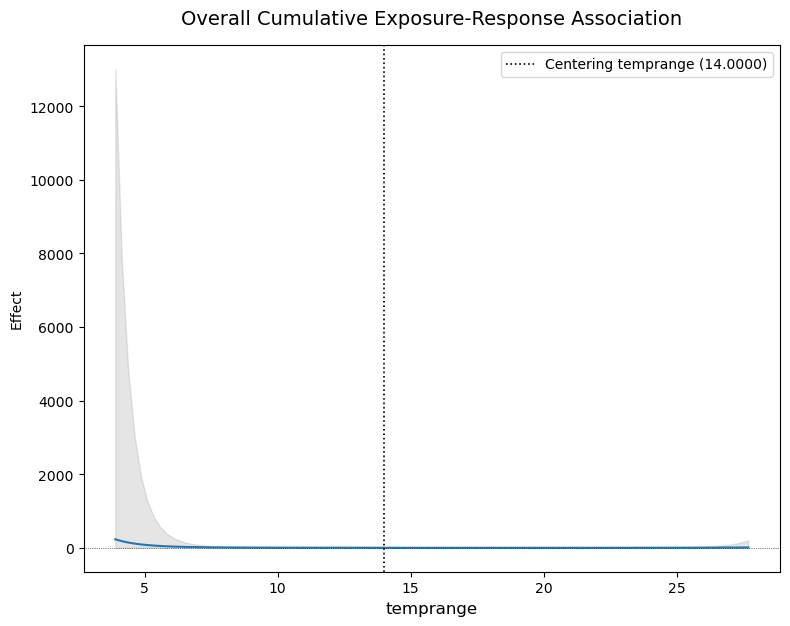

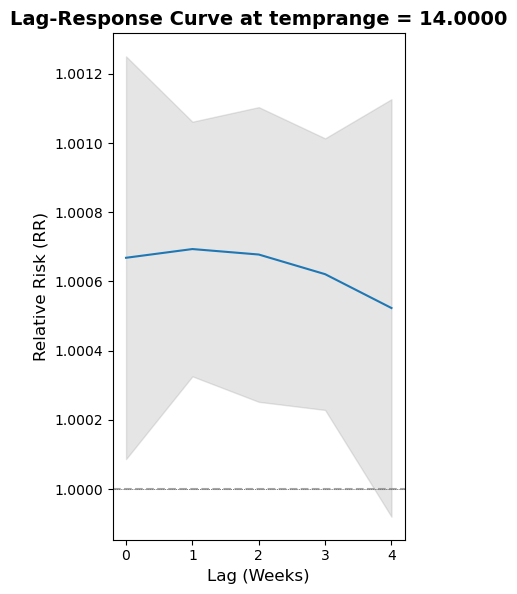

In [26]:
# Example: H1 ~ temprange (same call signature as original DLNM)
tar_var = "H1"
exp = mete_col[0]          # "temprange"
exp_col_list = [exp]

display(Markdown(f"**{'='*30} {exp} (ZINB) {'='*30}**"))

idata, pred, model_data, cb_list, colnames, nb_result = DLNM_ZINB(
    df,
    max_lag=4,
    tar_var=tar_var,
    exp_col_list=exp_col_list,
    linear_predictors_list=linear_predictors_list,
    bs_name_lst=bs_name_lst,
    ccs_name_lst=ccs_name_lst,
    cb_grid=cb_grid,
    smoother_grid=smoother_grid,
    disp_grid=disp_grid,
    criterion_lst=["bic", "gcv"],
    # PyMC controls – reduce draws/tune for a quick test
    draws=600,
    tune=600,
    target_accept=0.9,
    cores=2,
    psi_prior="constant",   # start simple; change to "logistic" later if needed
    prior_sigma=2.0,
)

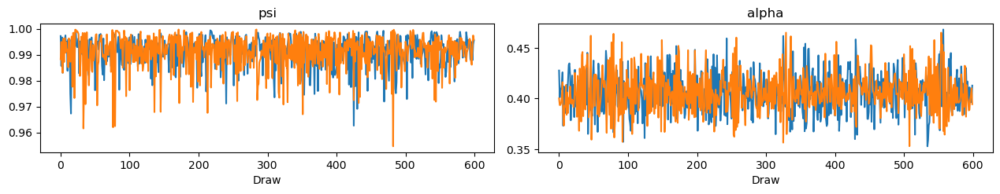

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
psi,0.9911,0.0065,0.98,1,1232,703,1.01,0.00017,0.00025
alpha,0.4062,0.02,0.38,0.44,1858,872,1.00,0.00046,0.00069


In [27]:
# Quick look at the ZINB posterior
az.plot_trace(idata, var_names=["psi", "alpha"])
plt.tight_layout()
plt.show()

az.summary(idata, var_names=["psi", "alpha"])

## Notes / next steps

1. **psi model** – The default is a global constant `psi`. Once that runs cleanly you can switch to `psi_prior="logistic"` so the zero-inflation probability also depends on the covariates / smoothers.
2. **Priors on the basis coefficients** – The current independent `Normal(0, prior_sigma)` is a reasonable weakly-informative choice. For stronger smoothness you can later replace it with a multivariate Normal that uses the penalty matrix from `cb_pen` / the smoother objects.
3. **Diagnostics** – Use `az.plot_ppc(idata)` for posterior predictive checks and compare the proportion of zeros in the data versus the posterior predictive distribution.
4. **Speed** – For exploratory work keep `draws`/`tune` modest (400–800). For final reporting increase them and consider `pm.sample(..., nuts_sampler="numpyro")` if you have JAX available.
5. The classic NegativeBinomial GLMGam result is still returned as `nb_result` so you can compare coefficients side-by-side with the ZINB posterior means.